#### Head-camera pointcloud with `ROBOTIS FFW SG2`

In [1]:
from package.init_scripts.init_ipython_setup import *
from package.init_scripts.init_qt import *
from package.mujoco_sim import *
from package.kinematics import *
from package.utility import *
from package.qt import *
from PyQt5.QtWidgets import QApplication
app = QApplication.instance() or QApplication(sys.argv)


[qt] package initialized.
Basic packages initialized.
 import numpy as np
 import matplotlib.pyplot as plt
 import scipy as sp
 from PIL import Image
[ipython] settings (retina, inline, qt) initialized.
[numpy] settings initialized.
[matplotlib] settings initialized.


In [2]:
xml_path = merge_mjcfs(
    included_mjcf_files=[
        "../asset/floor/floor_simple_white.xml",
        "../asset/robotis/robotis_ffw/ffw_sg2_site_added.xml",
        "../asset/object/table_0.xml",
        "../asset/objaverse/can/can_0/model_new.xml",
        "../asset/objaverse/can/can_2/model_new.xml",
        "../asset/objaverse/bowl/bowl_5/model_new.xml",
    ],
    output_xml_path = "xml/scene_ffw_sg2.xml",
)
env = MuJoCoParser(rel_xml_path=xml_path, verbose=False)


[merge_mjcfs] Merging [6] MJCF files:
  - [0] [../asset/floor/floor_simple_white.xml]
  - [1] [../asset/robotis/robotis_ffw/ffw_sg2_site_added.xml]
  - [2] [../asset/object/table_0.xml]
  - [3] [../asset/objaverse/can/can_0/model_new.xml]
  - [4] [../asset/objaverse/can/can_2/model_new.xml]
  - [5] [../asset/objaverse/bowl/bowl_5/model_new.xml]
[merge_mjcfs] Saved merged XML to:[xml/scene_ffw_sg2.xml]
MuJoCo model loaded from [xml/scene_ffw_sg2.xml].


In [3]:
# Reset
env.reset()
env.init_viewer(title="FFW SG2 Object / Camera PCD", width=1.0, height=1.0, fontscale=200)
env.viewer.set_cam_info(180, 3.2, -30, [0.02, 0.01, 0.4])
env.viewer.set_transparency(transparent=False)
env.viewer.set_geomgroup(group_2=True, group_3=False)
env.viewer.set_sitegroup(group_0=False)

# Arrange
env.set_p(name="base_link", p=[0.2, 0, 0.0], type="base_body")
env.set_p("body_object_table_0", "body", (0.8, 0.0, 0.0))
env.set_p("body_obj_can_0", "base", (0.70, -0.30, 0.70))
env.set_p("body_obj_can_2", "base", (0.70, -0.10, 0.70))
env.set_p("body_obj_bowl_5", "base", (0.85, 0.00, 0.70))

# Joint configurations
joint_groups = group_by_prefix(
    items       = env.rev_pri_joint_names,
    prefix_dict = {
        "arm_l_joint_names": ["arm_l_joint"],
        "arm_r_joint_names": ["arm_r_joint"],
        "lift_joint_name":   ["lift_joint"],
        "head_joint_names":  ["head_joint"],
        "gripper_l_joint_name": ["gripper_l_joint1"],
        "gripper_r_joint_name": ["gripper_r_joint1"],
    },
)
use_ik_joint_names = joint_groups["arm_r_joint_names"] + joint_groups["arm_l_joint_names"] + joint_groups["lift_joint_name"]
use_head_joint_names = joint_groups["head_joint_names"]
use_gripper_joint_names = joint_groups["gripper_r_joint_name"]

# Camera target
p_cam_trgt = np.array([0.80, 0.0, 0.7])
def compute_head_q_for_target(env, head_joint_names, p_cam_trgt):
    joint_idxs = [env.joint_names.index(name) for name in head_joint_names]
    q_mins = np.asarray(env.joint_mins[joint_idxs], dtype=np.float64)
    q_maxs = np.asarray(env.joint_maxs[joint_idxs], dtype=np.float64)
    q_head = np.zeros(len(head_joint_names), dtype=np.float64)

    uv_head_to_lookat = np_uv(np.asarray(p_cam_trgt) - env.get_p(name="head_cam", type="body"))
    for j_idx, joint_name in enumerate(head_joint_names):
        if joint_name == "head_joint1":
            q_head[j_idx] = np.arctan2(uv_head_to_lookat[0], uv_head_to_lookat[2])
        elif joint_name == "head_joint2":
            q_head[j_idx] = np.arctan2(uv_head_to_lookat[1], uv_head_to_lookat[0])

    return np.clip(q_head, q_mins, q_maxs)

# Update
init_q_ik = [1.07, 0, 0, -2.57, 0, 0, 0] * 2 + [-0.25]
env.forward(q=init_q_ik, joint_names=use_ik_joint_names)
init_q_head = compute_head_q_for_target(env, use_head_joint_names, p_cam_trgt)
env.forward(q=init_q_head, joint_names=use_head_joint_names)
env.step(ctrl=[0.0], joint_names=use_gripper_joint_names, nstep=1)
env.set_zero_qvel()
print("init_q_head:", init_q_head)


init_q_head: [0.7 0. ]


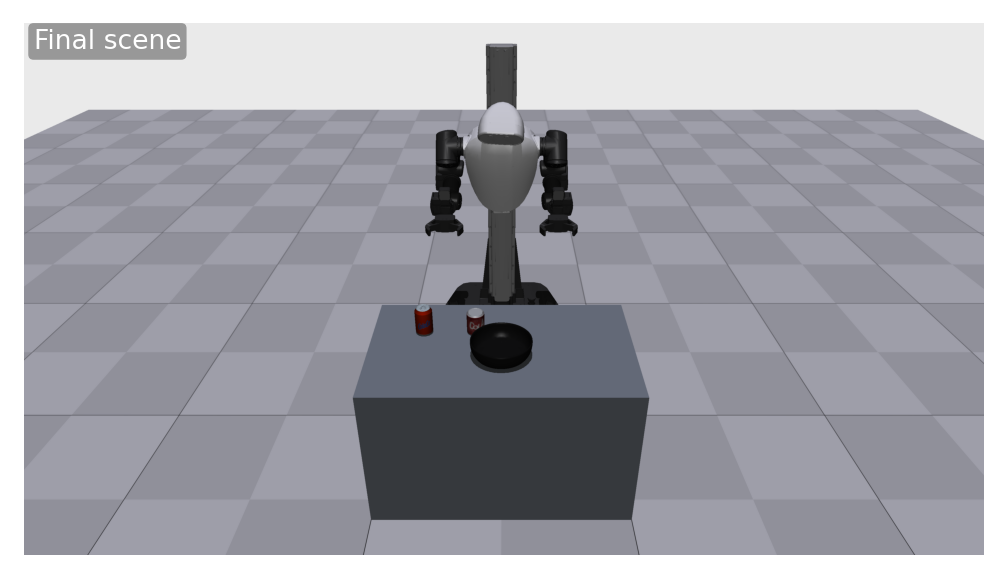

Done.


In [4]:
# Object names
obj_body_names = ["body_obj_can_0", "body_obj_can_2", "body_obj_bowl_5"]

# Controls
ctrl_vals = env.get_ctrl_qpos(ctrl_names=env.ctrl_names)
ctrl_mins = np.asarray(env.ctrl_mins, dtype=np.float64).copy()
ctrl_maxs = np.asarray(env.ctrl_maxs, dtype=np.float64).copy()
bad_range = (~np.isfinite(ctrl_mins)) | (~np.isfinite(ctrl_maxs)) | (ctrl_maxs <= ctrl_mins)
ctrl_mins[bad_range] = ctrl_vals[bad_range] - 1.0
ctrl_maxs[bad_range] = ctrl_vals[bad_range] + 1.0
ctrl_vals = np.clip(ctrl_vals, ctrl_mins, ctrl_maxs)
env.data.ctrl[:] = ctrl_vals.copy()

ctrl_name_to_idx = {name: idx for idx, name in enumerate(env.ctrl_names)}
head_ctrl_idxs = [ctrl_name_to_idx[name] for name in use_head_joint_names if name in ctrl_name_to_idx]
head_ctrl_names = [env.ctrl_names[idx] for idx in head_ctrl_idxs]
head_ctrl_vals = ctrl_vals[head_ctrl_idxs]
head_ctrl_mins = ctrl_mins[head_ctrl_idxs]
head_ctrl_maxs = ctrl_maxs[head_ctrl_idxs]

# Head slider
sliders_head = MultiSliderQtWidget(
    title         = "Head q ctrl",
    label_texts   = head_ctrl_names,
    slider_mins   = head_ctrl_mins,
    slider_maxs   = head_ctrl_maxs,
    slider_vals   = head_ctrl_vals,
    slider_steps  = 10000,
    x_offset      = 0.00,
    y_offset      = 0.05,
    window_width  = 0.25,
    window_height = 0.16,
    fontsize      = 30,
)
cam_target_dist = np.linalg.norm(p_cam_trgt - env.get_p("head_cam", type="body"))
sim_nstep  = 20
tmr_sim    = SimpleTimer(name="Sim", Hz=1.0 / (env.dt * sim_nstep), verbose=True)
tmr_render = SimpleTimer(name="Render", Hz=15, verbose=True)
tmr_sim.start(); tmr_render.start(); env.reset_wall_time(); env.reset_sim_time()

while env.is_viewer_alive():
    app.processEvents()

    if tmr_sim.do_run():
        ctrl_vals[head_ctrl_idxs] = sliders_head.get_values()
        env.compensate_gravity(root_body_names=["base_link"], on=True)
        env.step(ctrl=ctrl_vals, nstep=sim_nstep)
        tmr_sim.end()

    if tmr_render.do_run():
        T_head_cam = env.get_T("head_cam", type="body")
        p_head_cam = T_head_cam[:3, 3]
        p_cam_trgt = p_head_cam + cam_target_dist * np_uv(T_head_cam[:3, 0])
        rgb_img, depth_img, cam_pcd, xyz_img, xyz_img_world = env.get_egocentric_rgbd_pcd(
            p_ego            = p_head_cam,
            p_trgt           = p_cam_trgt,
            rsz_rate_for_pcd = 1 / 4,
            rsz_rate_for_img = 1 / 2,
            fovy             = 45,
            restore_view     = True,
        )
        env.plot_time(plot_loop_freq=False)
        env.plot_global_coordinate_axes()
        env.plot_contact_info(plot_contact=True, rate=0.5)
        env.plot_T(T=env.get_T("head_cam", "body"), axis_len=0.06, axis_width=0.004)
        env.plot_sphere(p=p_cam_trgt, r=0.005, rgba=(1, 0, 0, 0.5), label="cam target")
        for body_name in obj_body_names:
            env.plot_T(T=env.get_T(body_name, "body"), axis_len=0.04, axis_width=0.003)
        valid = np.isfinite(cam_pcd).all(axis=1)
        cam_pcd_vis = cam_pcd[valid]
        cam_pcd_vis = cam_pcd_vis[::max(1, len(cam_pcd_vis) // 5000)]
        env.plot_spheres(cam_pcd_vis, r=0.002, rgba=(0,1,1,0.5))
        env.viewer.plot_rgb_overlay(rgb_img, loc="top right")

        env.render()
        tmr_render.end()

final_rgb_img = getattr(env, "final_rgb_img", None)
env.close_viewer()
sliders_head.close()
if final_rgb_img is not None:
    imshow(final_rgb_img, fig_w=4, title="Final scene", title_fs=8)
print_green("Done.")
